# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy (test): 0.9722
F1 macro (test): 0.9710
Accuracy CV (entrenamiento): 0.9791 ± 0.0277

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        12
           1      0.933     1.000     0.966        14
           2      1.000     0.900     0.947        10

    accuracy                          0.972        36
   macro avg      0.978     0.967     0.971        36
weighted avg      0.974     0.972     0.972        36



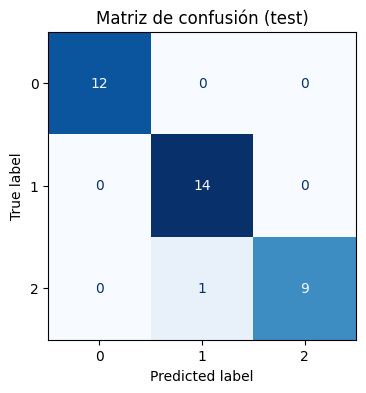

Muestras mal clasificadas: 1 de 36


In [4]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy (test): {accuracy:.4f}")
print(f"F1 macro (test): {f1_macro:.4f}")
print(f"Accuracy CV (entrenamiento): {training_metadata['cv_accuracy']:.4f} ± {training_metadata['cv_std']:.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (test)")
plt.show()

errores = test_df[y_test.values != y_pred]
print("Muestras mal clasificadas:", len(errores), "de", len(test_df))

**Análisis:**

> - **Coherencia con la CV:** la accuracy en test es **0.9722** (35 de 36 aciertos) y el F1 macro **0.9710**, frente a **0.9791 ± 0.0277** en CV. La diferencia (≈ 0.7 puntos) está muy dentro de la desviación entre folds, así que el resultado es coherente.
> - **Clases confundidas:** hubo un solo error: **un vino de la clase 2 predicho como clase 1** (recall de la clase 2 = 0.90 y precisión de la clase 1 = 0.933). La clase 0 se clasificó perfectamente.
> - **Sobreajuste:** no hay evidencia; si el modelo hubiera memorizado el entrenamiento, el desempeño en test habría caído de forma notable respecto a la CV.
> - **Cautela:** el test tiene solo 36 muestras, y cada error cuesta ≈ 2.8 puntos de accuracy, por lo que esta estimación es poco precisa.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verifica columnas faltantes
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Ordena las columnas como feature_columns (ignora columnas extra)
    X = records[feature_columns]

    # Devuelve prediction y probabilidades
    out = pd.DataFrame({"prediction": model.predict(X)}, index=records.index)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        for k, cls in enumerate(model.classes_):
            out[f"proba_class_{cls}"] = proba[:, k].round(4)
    return out

# Comprobación del esquema: debe fallar si falta una columna
try:
    predict(X_test.drop(columns=["proline"]).iloc[:2])
except ValueError as e:
    print("Validación OK ->", e)

Validación OK -> Faltan columnas requeridas: ['proline']


## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch = predict(new_records)
batch_out = pd.concat([new_records, batch], axis=1)
batch_out.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
batch_out[["prediction"] + [c for c in batch_out.columns if c.startswith("proba")]]

,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


## 5. Reporte final

In [7]:
metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(accuracy),
    "f1_macro": float(f1_macro),
}
(REPORTS_DIR / "test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(metrics)

{'model': 'logistic_regression', 'accuracy': 0.9722222222222222, 'f1_macro': 0.9709618874773139}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (`C = 1`) con `StandardScaler` |
| Accuracy CV | 0.979 ± 0.028 |
| Accuracy test | 0.972 (35 de 36) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 ↔ clase 1 (un vino de la clase 2 predicho como clase 1) |
| Principal limitación | Dataset pequeño (178 vinos; 36 en test): la estimación es imprecisa y no se ha probado con vinos de otras fuentes |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.